# Optimización de pipelines y eficiencia en tiempo real

Se desarrollará un sistema de detección y seguimiento de manos en tiempo real utilizando la cámara integrada de un Mac, OpenCV y MediaPipe

El sistema identificará los 21 puntos de referencia anatómicos (landmarks) de cada mano y representará sus conexiones sobre el video mientras se realiza una actividad manual de bordado punch needle

El desafío no consiste en desarrollar un nuevo modelo predictivo, sino en optimizar la arquitectura de procesamiento para reducir retrasos, mantener una visualización fluida y utilizar eficientemente los recursos computacionales

## Preparación del entorno

In [1]:
import sys
import time
import platform
import threading
import queue
import urllib.request

from pathlib import Path

import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil

import ipywidgets as widgets

from IPython.display import display

import queue
import threading
import psutil
import pandas as pd

from IPython.display import display, clear_output
from cv2_enumerate_cameras import enumerate_cameras

In [2]:
environment = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "processor": platform.processor(),
    "opencv": cv2.__version__,
    "mediapipe": mp.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "cpu_cores": psutil.cpu_count(logical=True),
    "memory_gb": round(psutil.virtual_memory().total / (1024**3), 2)
}

display(pd.DataFrame(environment.items(), columns=["Componente", "Valor"]))

,Componente,Valor
0,python,3.11.16
1,platform,macOS-27.0.1-arm64-arm-64bit
2,processor,arm
3,opencv,5.0.0
4,mediapipe,1.1.0
5,numpy,2.4.6
6,pandas,3.0.6
7,cpu_cores,12
8,memory_gb,36.0


### Configuración experimental

In [3]:
cameras = list(enumerate_cameras(cv2.CAP_AVFOUNDATION))

for camera in cameras:
    print(
        f"Índice: {camera.index} | "
        f"Nombre: {camera.name}"
    )

Índice: 0 | Nombre: Studio Display Camera
Índice: 1 | Nombre: FaceTime HD Camera


In [4]:
CAMERA_INDEX = 1
FRAME_WIDTH = 640
FRAME_HEIGHT = 480
MAX_HANDS = 2
DETECTION_CONFIDENCE = 0.5
PRESENCE_CONFIDENCE = 0.5
TRACKING_CONFIDENCE = 0.5
WARMUP_SECONDS = 5
EXPERIMENT_SECONDS = 300
QUEUE_SIZE = 1
DISPLAY_MAX_FPS = 10
JPEG_QUALITY = 75
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

In [5]:
print("EXPERIMENT_SECONDS:", EXPERIMENT_SECONDS)
print("WARMUP_SECONDS:", WARMUP_SECONDS)

EXPERIMENT_SECONDS: 300
WARMUP_SECONDS: 5


## Captura de video en tiempo real

In [6]:
def open_camera():
    camera = cv2.VideoCapture(CAMERA_INDEX, cv2.CAP_AVFOUNDATION)

    if not camera.isOpened():
        raise RuntimeError(f"No se pudo abrir la cámara con índice {CAMERA_INDEX}.")

    camera.set(cv2.CAP_PROP_FRAME_WIDTH, FRAME_WIDTH)
    camera.set(cv2.CAP_PROP_FRAME_HEIGHT, FRAME_HEIGHT)

    return camera

### Comprobación de captura

In [7]:
camera = open_camera()
success, frame = camera.read()
camera.release()

if not success:
    raise RuntimeError("No se recibió ninguna imagen.")

print("Shape:", frame.shape)
print("Tipo:", frame.dtype)
print("Tamaño:", frame.nbytes, "bytes")

Shape: (480, 640, 3)
Tipo: uint8
Tamaño: 921600 bytes


## Detección de manos mediante MediaPipe

In [8]:
MODEL_PATH = Path("hand_landmarker.task")

MODEL_URL = (
    "https://storage.googleapis.com/"
    "mediapipe-models/hand_landmarker/"
    "hand_landmarker/float16/1/"
    "hand_landmarker.task"
)

if not MODEL_PATH.exists():
    urllib.request.urlretrieve(
        MODEL_URL,
        MODEL_PATH
    )

print("Modelo:", MODEL_PATH)
print("Tamaño:", MODEL_PATH.stat().st_size, "bytes")

Modelo: hand_landmarker.task
Tamaño: 7819105 bytes


### Inicialización del detector

In [9]:
BaseOptions = mp.tasks.BaseOptions
HandLandmarker = mp.tasks.vision.HandLandmarker
HandLandmarkerOptions = mp.tasks.vision.HandLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode


def create_detector():

    options = HandLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=str(MODEL_PATH)),
        running_mode=VisionRunningMode.VIDEO,
        num_hands=MAX_HANDS,
        min_hand_detection_confidence=DETECTION_CONFIDENCE,
        min_hand_presence_confidence=PRESENCE_CONFIDENCE,
        min_tracking_confidence=TRACKING_CONFIDENCE
    )

    return HandLandmarker.create_from_options(options)

### Preprocesamiento e inferencia

In [10]:
def detect_hands(detector, frame, timestamp_ms):
    start_preprocess = time.perf_counter()
    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)
    preprocess_ms = (time.perf_counter() - start_preprocess) * 1000
    start_inference = time.perf_counter()
    result = detector.detect_for_video(mp_image, timestamp_ms)
    inference_ms = (time.perf_counter() - start_inference) * 1000

    return result, preprocess_ms, inference_ms

### Representación visual de los landmarks

In [11]:
HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4),
    (0, 5), (5, 6), (6, 7), (7, 8),
    (5, 9), (9, 10), (10, 11), (11, 12),
    (9, 13), (13, 14), (14, 15), (15, 16),
    (13, 17), (17, 18), (18, 19), (19, 20),
    (0, 17)
]

def draw_hands(frame, result):
    output = frame.copy()
    height, width = output.shape[:2]

    for hand in result.hand_landmarks:
        points = []
        for landmark in hand:
            x = int(landmark.x * width)
            y = int(landmark.y * height)
            points.append((x, y))

        for start, end in HAND_CONNECTIONS:
            cv2.line(output, points[start], points[end], (0, 255, 0), 2)

        for point in points:
            cv2.circle(output, point, 3, (0, 0, 255), -1)
    return output

### Comprobación funcional del detector

Manos detectadas: 2
Preprocesamiento: 0.33 ms
Inferencia: 32.62 ms


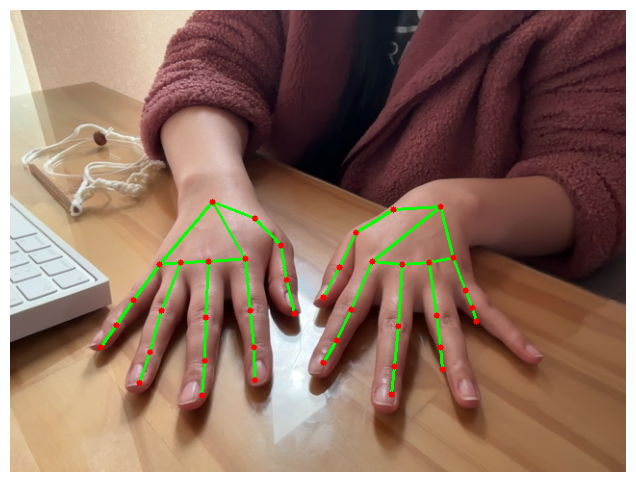

In [12]:
CAPTURE_DELAY = 3
camera = open_camera()
frame = None

try:
    start_time = time.perf_counter()
    last_second = None

    while True:
        success, current_frame = camera.read()
        if not success:
            raise RuntimeError("No se pudo leer la cámara.")

        elapsed = time.perf_counter() - start_time
        remaining = max(0, int(np.ceil(CAPTURE_DELAY - elapsed)))

        if remaining != last_second:
            clear_output(wait=True)
            print(f"Captura automática en {remaining} segundos")
            last_second = remaining

        if elapsed >= CAPTURE_DELAY:
            frame = current_frame.copy()
            break

finally:
    camera.release()

if frame is not None:
    with create_detector() as detector:
        result, preprocess_ms, inference_ms = detect_hands(detector, frame, timestamp_ms=1)

    output = draw_hands(frame, result)
    clear_output(wait=True)

    print("Manos detectadas:", len(result.hand_landmarks))
    print(f"Preprocesamiento: {preprocess_ms:.2f} ms")
    print(f"Inferencia: {inference_ms:.2f} ms")

    plt.figure(figsize=(9, 6))
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

## Implementación del pipeline síncrono en tiempo real

### Creación del visualizador

In [13]:
def create_viewer(title):
    image_widget = widgets.Image(format="jpeg", width=FRAME_WIDTH, height=FRAME_HEIGHT)
    status_widget = widgets.HTML(value="<b>Preparando captura...</b>")

    viewer = widgets.VBox([
        widgets.HTML(f"<h4>{title}</h4>"),
        image_widget,
        status_widget
    ])

    display(viewer)
    return image_widget, status_widget

### Conversión de imágenes

In [14]:
def encode_frame(frame):
    success, buffer = cv2.imencode(".jpg",frame,[cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])

    if not success:
        raise RuntimeError("No fue posible codificar la imagen.")

    return buffer.tobytes()

### Diseño de las métricas de rendimiento

| Métrica | Unidad | Interpretación |
|---|---|---|
| FPS procesados | frames/s | Imágenes que completan la inferencia por segundo |
| FPS enviados a visualización | actualizaciones/s | Imágenes entregadas al widget por segundo |
| Latencia extremo a extremo | ms | Desde la recepción del frame hasta completar su entrega al widget |
| Inferencia | ms | Tiempo dedicado a MediaPipe |
| Preprocesamiento | ms | Conversión de imagen y preparación para MediaPipe |
| P50, P95, P99 | ms | Distribución de latencia |
| CPU | % | Consumo del proceso Python |
| Memoria | MB | Memoria del proceso |
| Frames descartados | cantidad | Imágenes perdidas por la política de colas |

### Función de cálculo de métricas 

In [15]:
def summarize_performance(
    records,
    mode,
    duration,
    processed_frames,
    display_updates,
    cpu_samples
):

    df = pd.DataFrame(records)

    if df.empty:
        raise RuntimeError("No se registraron mediciones.")

    latency = df["latency_ms"]
    inference = df["inference_ms"]

    summary = {
        "mode": mode,
        "processed_frames": processed_frames,
        "display_updates": display_updates,
        "processing_fps": (processed_frames / duration),
        "display_update_fps": (display_updates / duration),
        "latency_mean_ms": latency.mean(),
        "latency_p50_ms": latency.quantile(0.50),
        "latency_p95_ms": latency.quantile(0.95),
        "latency_p99_ms": latency.quantile(0.99),
        "inference_mean_ms": inference.mean(),
        "inference_p95_ms": inference.quantile(0.95),
        "capture_mean_ms": df["capture_ms"].mean(),
        "preprocess_mean_ms": df["preprocess_ms"].mean(),
        "render_mean_ms": df["render_ms"].mean(),
        "cpu_mean_percent": (np.mean(cpu_samples) if cpu_samples else np.nan),
        "memory_peak_mb": df["memory_mb"].max(),
        "hand_detection_rate": (df["hands_detected"] > 0).mean()
    }
    return df, summary

### Construcción del pipeline síncrono 

In [16]:
def run_synchronous():

    image_widget, status_widget = create_viewer("Experimento 1: Pipeline síncrono")
    camera = open_camera()
    process = psutil.Process()
    process.cpu_percent(interval=None)

    records = []
    cpu_samples = []
    processed_frames = 0
    display_updates = 0
    session_start = time.perf_counter()

    measurement_start = (session_start + WARMUP_SECONDS)
    measurement_end = (measurement_start + EXPERIMENT_SECONDS)
    last_display = 0
    last_cpu_sample = measurement_start
    last_timestamp_ms = -1
    measurement_duration = 0

    try:
        with create_detector() as detector:
            while time.perf_counter() < measurement_end:
                capture_start = time.perf_counter()
                success, frame = camera.read()
                captured_at = time.perf_counter()

                if not success:
                    raise RuntimeError("Se perdió la captura de la cámara.")

                timestamp_ms = max(
                    int((captured_at - session_start) * 1000),
                    last_timestamp_ms + 1
                )

                last_timestamp_ms = timestamp_ms
                result, preprocess_ms, inference_ms = detect_hands(detector, frame, timestamp_ms)

                inference_completed = time.perf_counter()
                render_start = time.perf_counter()
                output = draw_hands(frame, result)

                should_display = (inference_completed - last_display >= 1 / DISPLAY_MAX_FPS)

                if should_display:
                    cv2.putText(
                        output,
                        "SYNC",
                        (15, 30),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.8,
                        (255, 255, 255),
                        2
                    )

                    image_widget.value = encode_frame(output)
                    last_display = time.perf_counter()
                completed_at = time.perf_counter()

                if completed_at >= measurement_start:
                    processed_frames += 1
                    if should_display:
                        display_updates += 1

                    memory_mb = (process.memory_info().rss / (1024**2))

                    records.append({
                        "frame_id": processed_frames,
                        "timestamp": completed_at,
                        "capture_ms": (captured_at - capture_start) * 1000,
                        "preprocess_ms": preprocess_ms,
                        "inference_ms": inference_ms,
                        "render_ms": (completed_at - render_start) * 1000,
                        "latency_ms": (completed_at - captured_at) * 1000,
                        "hands_detected": len(result.hand_landmarks),
                        "memory_mb": memory_mb
                    })

                    if (completed_at - last_cpu_sample >= 1.0):
                        cpu_samples.append(process.cpu_percent(interval=None))
                        last_cpu_sample = completed_at

                    current_fps = (
                        processed_frames /
                        max(completed_at - measurement_start, 1e-9)
                    )

                    status_widget.value = (
                        f"FPS procesados: {current_fps:.1f}"
                        f" | Inferencia: {inference_ms:.1f} ms"
                        f" | Manos: {len(result.hand_landmarks)}"
                    )
    finally:

        measurement_duration = max(
            0,
            min(time.perf_counter(), measurement_end)
            - measurement_start
        )

        camera.release()
        status_widget.value += ("<br><b>Captura finalizada</b>")

    return summarize_performance(
        records,
        "sync",
        measurement_duration,
        processed_frames,
        display_updates,
        cpu_samples
    )

### Ejecución del primer experimento

In [17]:
start = time.perf_counter()

df_sync, summary_sync = run_synchronous()

elapsed = time.perf_counter() - start

print(f"Duración real: {elapsed:.2f} segundos")
print(f"Duración real: {elapsed / 60:.2f} minutos")

W0000 00:00:1791756458.299112  964732 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791756458.302089  964736 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Duración real: 305.55 segundos
Duración real: 5.09 minutos


### Comprobación numérica

In [18]:
display(pd.DataFrame([summary_sync]).T.rename(columns={0: "Baseline"}))

,Baseline
mode,sync
processed_frames,8721
display_updates,2349
processing_fps,29.07
display_update_fps,7.83
latency_mean_ms,20.389743
latency_p50_ms,19.458417
latency_p95_ms,22.592083
latency_p99_ms,37.3736
inference_mean_ms,19.852849


In [19]:
assert len(df_sync) > 0
assert summary_sync["processing_fps"] > 0
assert (df_sync["latency_ms"] >= 0).all()
assert (df_sync["inference_ms"] >= 0).all()

### Almacenamiento de los resultados

In [20]:
df_sync.to_csv(RESULTS_DIR / "sync_frames.csv", index=False)
pd.DataFrame([summary_sync]).to_csv(RESULTS_DIR / "sync_summary.csv", index=False)

## Optimización del pipeline mediante programación concurrente

In [21]:
def put_latest(q, item):
    dropped = 0

    try:
        q.put_nowait(item)
    except queue.Full:
        try:
            q.get_nowait()
            dropped += 1
        except queue.Empty:
            pass

        try:
            q.put_nowait(item)
        except queue.Full:
            dropped += 1
    return dropped

In [22]:
def capture_worker(frame_queue, stop_event, stats, errors, session_start):
    camera = None

    try:
        camera = open_camera()
        frame_id = 0

        while not stop_event.is_set():
            capture_start = time.perf_counter()
            success, frame = camera.read()
            captured_at = time.perf_counter()

            if not success:
                raise RuntimeError("La cámara dejó de entregar imágenes.")

            frame_id += 1
            item = {
                "frame_id": frame_id,
                "frame": frame,
                "captured_at": captured_at,
                "capture_ms": (captured_at - capture_start) * 1000,
                "timestamp_ms": int((captured_at - session_start) * 1000)
            }
            dropped = put_latest(frame_queue, item)
            stats["captured"] += 1
            stats["dropped_input"] += dropped

    except Exception as exc:
        errors.append(f"Captura: {type(exc).__name__}: {exc}")
        stop_event.set()

    finally:
        if camera is not None:
            camera.release()

In [ ]:
def inference_worker(frame_queue, result_queue, stop_event, stats, errors):
    try:
        with create_detector() as detector:
            last_timestamp_ms = -1
            while not stop_event.is_set():
                try:
                    item = frame_queue.get(timeout=0.1)

                except queue.Empty:
                    continue

                timestamp_ms = max(item["timestamp_ms"], last_timestamp_ms + 1)
                last_timestamp_ms = timestamp_ms

                result, preprocess_ms, inference_ms = detect_hands(detector, item["frame"], timestamp_ms)

                item["result"] = result
                item["preprocess_ms"] = preprocess_ms
                item["inference_ms"] = inference_ms
                item["inference_completed"] = time.perf_counter()
                stats["processed"] += 1

                dropped = put_latest(result_queue, item)
                stats["dropped_output"] += dropped
    except Exception as exc:
        errors.append(f"Inferencia: {type(exc).__name__}: {exc}")
        stop_event.set()

In [ ]:
def run_asynchronous():
    image_widget, status_widget = create_viewer("Experimento 2: Pipeline concurrente")

    frame_queue = queue.Queue(maxsize=QUEUE_SIZE)
    result_queue = queue.Queue(maxsize=QUEUE_SIZE)
    stop_event = threading.Event()

    stats = {
        "captured": 0,
        "processed": 0,
        "dropped_input": 0,
        "dropped_output": 0
    }

    errors = []

    records = []
    cpu_samples = []
    process = psutil.Process()
    process.cpu_percent(interval=None)
    session_start = time.perf_counter()
    measurement_start = (session_start + WARMUP_SECONDS)
    measurement_end = (measurement_start + EXPERIMENT_SECONDS)

    capture_thread = threading.Thread(
        target=capture_worker,
        args=(frame_queue, stop_event, stats, errors, session_start),
        name="CaptureThread"
    )

    inference_thread = threading.Thread(
        target=inference_worker,
        args=(frame_queue, result_queue, stop_event, stats, errors),
        name="InferenceThread"
    )

    display_updates = 0
    last_display = 0
    last_cpu_sample = measurement_start
    last_frame_id = -1
    observed_results = 0
    last_result = None
    measurement_duration = 0
    capture_thread.start()
    inference_thread.start()

    try:
        while (time.perf_counter() < measurement_end and not stop_event.is_set()):
            try:
                item = result_queue.get(timeout=0.1)
            except queue.Empty:
                continue

            completed_at = time.perf_counter()
            render_start = completed_at
            output = draw_hands(item["frame"], item["result"])
            should_display = (completed_at - last_display >= 1 / DISPLAY_MAX_FPS)

            if should_display:
                cv2.putText(output, "ASYNC", (15, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
                image_widget.value = encode_frame(output)
                last_display = time.perf_counter()

            rendered_at = time.perf_counter()

            if item["captured_at"] >= measurement_start:
                observed_results += 1
                last_result = item

                if should_display:
                    display_updates += 1

                assert item["frame_id"] > last_frame_id
                last_frame_id = item["frame_id"]

                records.append({
                    "frame_id": item["frame_id"],
                    "timestamp": rendered_at,
                    "capture_ms": item["capture_ms"],
                    "preprocess_ms": item["preprocess_ms"],
                    "inference_ms": item["inference_ms"],
                    "render_ms": (rendered_at - render_start) * 1000,
                    "latency_ms": (rendered_at - item["captured_at"]) * 1000,
                    "hands_detected": len(item["result"].hand_landmarks),
                    "memory_mb": (process.memory_info().rss / (1024**2))
                })

                if (rendered_at - last_cpu_sample >= 1.0):
                    cpu_samples.append(process.cpu_percent(interval=None))
                    last_cpu_sample = rendered_at

                current_fps = (observed_results / max(rendered_at - measurement_start, 1e-9))

                status_widget.value = (
                    f"FPS resultados: {current_fps:.1f}"
                    f" | Inferencia: {item['inference_ms']:.1f} ms"
                    f" | Manos: {len(item['result'].hand_landmarks)}"
                )

    finally:
        measurement_duration = max(0, min(time.perf_counter(), measurement_end) - measurement_start)
        stop_event.set()
        capture_thread.join(timeout=5)
        inference_thread.join(timeout=5)
        alive = [thread.name for thread in (capture_thread, inference_thread) if thread.is_alive()]

        if alive:
            raise RuntimeError(
                "No se cerraron correctamente los hilos: "
                + ", ".join(alive)
                + ". No reinicies la captura hasta resolverlo."
            )
        status_widget.value += ("<br><b>Captura finalizada</b>")

    if errors:
        raise RuntimeError("; ".join(errors))

    processed_frames = observed_results

    df, summary = summarize_performance(
        records,
        "async",
        measurement_duration,
        processed_frames,
        display_updates,
        cpu_samples
    )

    summary["captured_total"] = stats["captured"]
    summary["processed_total"] = stats["processed"]
    summary["dropped_input"] = stats["dropped_input"]
    summary["dropped_output"] = stats["dropped_output"]
    summary["drop_rate"] = (stats["dropped_input"] / max(stats["captured"], 1))
    summary["results_observed"] = observed_results

    return df, summary

### Ejecución del experimento optimizado

In [25]:
start = time.perf_counter()

df_async, summary_async = run_asynchronous()

elapsed = time.perf_counter() - start

print(f"Duración real: {elapsed:.2f} segundos")
print(f"Duración real: {elapsed / 60:.2f} minutos")

W0000 00:00:1791756763.590348  977335 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791756763.593494  977341 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Duración real: 305.08 segundos
Duración real: 5.08 minutos


In [26]:
display(pd.DataFrame([summary_async]).T.rename(columns={0: "Concurrente"}))

,Concurrente
mode,async
processed_frames,7803
display_updates,2351
processing_fps,26.01
display_update_fps,7.836667
latency_mean_ms,20.340835
latency_p50_ms,19.38875
latency_p95_ms,26.031251
latency_p99_ms,35.681052
inference_mean_ms,19.744622


In [27]:
assert len(df_async) > 0
assert df_async["frame_id"].is_unique
assert df_async["frame_id"].is_monotonic_increasing
assert (df_async["latency_ms"] >= 0).all()
assert (df_async["inference_ms"] >= 0).all()

In [28]:
df_async.to_csv(RESULTS_DIR / "async_frames.csv", index=False)
pd.DataFrame([summary_async]).to_csv(RESULTS_DIR / "async_summary.csv", index=False)

## Benchmarking y análisis comparativo

En las secciones anteriores se implementaron y evaluaron dos arquitecturas para el reconocimiento de manos en tiempo real mediante MediaPipe Hand Landmarker

| Experimento | Arquitectura | Resultados |
|---|---|---|
| 1 | Síncrona | `df_sync`, `summary_sync` |
| 2 | Concurrente | `df_async`, `summary_async` |

En esta sección se analizarán los datos obtenidos durante ambos experimentos, sin realizar nuevas capturas. El objetivo será comparar el rendimiento de las arquitecturas a partir de cuatro aspectos:

1. Capacidad de procesamiento, medida en FPS.
2. Latencia de procesamiento y visualización.
3. Estabilidad del rendimiento durante la ejecución.
4. Consumo de recursos computacionales.

### Protocolo experimental

Ambas arquitecturas se evaluaron utilizando la cámara del MacBook para reconocer los movimientos de las manos durante una actividad de tejido. Se establecieron las siguientes condiciones para facilitar la comparación:

| Variable | Condición experimental |
|---|---|
| Cámara | FaceTime HD Camera del MacBook |
| Resolución solicitada | 640 × 480 píxeles |
| Modelo | MediaPipe Hand Landmarker |
| Manos máximas | 2 |
| Duración configurada | 60 segundos |
| Calentamiento configurado | 5 segundos |
| Visualización | ipywidgets, máximo 10 actualizaciones/s |
| Actividad | Tejido |
| Hardware | Mismo MacBook |

La duración y las demás condiciones corresponden a los parámetros configurados en el código. En las siguientes secciones se verificará la cantidad real de datos registrados

In [29]:
assert not df_sync.empty, "No hay datos del pipeline síncrono"
assert not df_async.empty, "No hay datos del pipeline concurrente"

print("Pipeline síncrono:")
print("Frames registrados:", len(df_sync))

print("\nPipeline concurrente:")
print("Frames registrados:", len(df_async))

Pipeline síncrono:
Frames registrados: 8721

Pipeline concurrente:
Frames registrados: 7803


### Comparación general de rendimiento

In [30]:
comparison = pd.DataFrame([summary_sync, summary_async])

columns = [
    "mode",
    "processing_fps",
    "display_update_fps",
    "latency_mean_ms",
    "latency_p50_ms",
    "latency_p95_ms",
    "latency_p99_ms",
    "inference_mean_ms",
    "cpu_mean_percent",
    "memory_peak_mb"
]

display(comparison[columns].round(2))

,mode,processing_fps,display_update_fps,latency_mean_ms,latency_p50_ms,latency_p95_ms,latency_p99_ms,inference_mean_ms,cpu_mean_percent,memory_peak_mb
0,sync,29.07,7.83,20.39,19.46,22.59,37.37,19.85,66.80,501.05
1,async,26.01,7.84,20.34,19.39,26.03,35.68,19.74,59.18,524.81


### Comparación visual de FPS

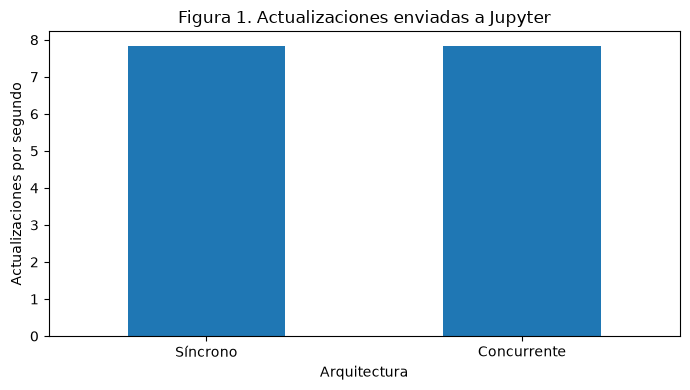

In [31]:
fps_comparison = comparison[["mode", "display_update_fps"]].copy()
fps_comparison["mode"] = fps_comparison["mode"].replace({"sync": "Síncrono", "async": "Concurrente"})

ax = fps_comparison.plot(x="mode", y="display_update_fps", kind="bar", legend=False, figsize=(7, 4))
ax.set_title("Figura 1. Actualizaciones enviadas a Jupyter")
ax.set_xlabel("Arquitectura")
ax.set_ylabel("Actualizaciones por segundo")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Ambas arquitecturas presentaron una frecuencia de actualización prácticamente idéntica: 7.83 actualizaciones por segundo en el pipeline síncrono y 7.84 en el concurrente

A pesar de que la arquitectura síncrona registró un mayor rendimiento de procesamiento, esta ventaja no se reflejó en la frecuencia de imágenes enviadas a Jupyter. Ambas configuraciones permanecieron por debajo del límite de 10 actualizaciones por segundo establecido para la visualización

Estos resultados indican que la concurrencia no produjo una mejora apreciable en la frecuencia de actualización visual

### Comparación del rendimiento de procesamiento

In [32]:
display(comparison[["mode", "processing_fps", "display_update_fps"]].round(2))

,mode,processing_fps,display_update_fps
0,sync,29.07,7.83
1,async,26.01,7.84


El pipeline síncrono registró 29.07 FPS frente a 26.01 FPS del concurrente, lo que representa un rendimiento aproximadamente un 11.8 % superior respecto a este último. Sin embargo, esta diferencia no se reflejó en la visualización ya que ambas arquitecturas enviaron prácticamente la misma cantidad de actualizaciones a Jupyter: 7.83 y 7.84 por segundo+

### Análisis de latencia

In [33]:
latency_comparison = pd.DataFrame({
    "P50": [summary_sync["latency_p50_ms"], summary_async["latency_p50_ms"]],
    "P95": [summary_sync["latency_p95_ms"], summary_async["latency_p95_ms"]],
    "P99": [summary_sync["latency_p99_ms"], summary_async["latency_p99_ms"]]
}, index=["Síncrono", "Concurrente"])

display(latency_comparison.round(2))

,P50,P95,P99
Síncrono,19.46,22.59,37.37
Concurrente,19.39,26.03,35.68


Ambas arquitecturas presentaron una mediana (P50) cercana a 19.4 ms, lo que indica tiempos de respuesta habituales similares. No obstante, el pipeline concurrente registró una P95 mayor (26.03 ms frente a 22.59 ms), mientras que su P99 fue ligeramente menor (35.68 ms frente a 37.37 ms)

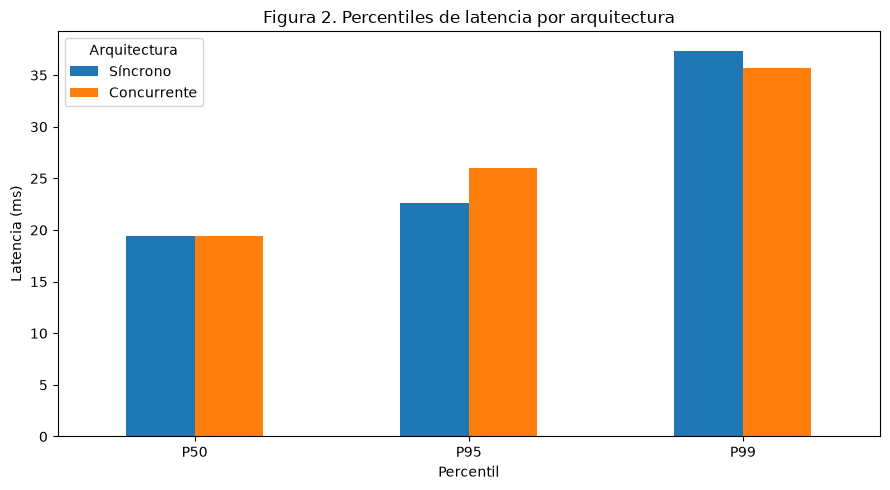

In [34]:
ax = latency_comparison.T.plot(kind="bar", figsize=(9, 5))
ax.set_title("Figura 2. Percentiles de latencia por arquitectura")
ax.set_xlabel("Percentil")
ax.set_ylabel("Latencia (ms)")

plt.xticks(rotation=0)
plt.legend(title="Arquitectura")
plt.tight_layout()
plt.show()

Ambas arquitecturas presentaron una latencia mediana prácticamente idéntica, cercana a 19.4 ms, lo que indica un comportamiento similar en los tiempos de respuesta habituales

Sin embargo, en el percentil 95, la arquitectura concurrente registró 26.03 ms frente a 22.59 ms de la síncrona, representando un incremento aproximado del 15.2 %. Esto evidencia que la concurrencia no consiguió reducir los retrasos elevados y que el pipeline síncrono presentó un mejor comportamiento en este percentil

In [35]:
latency_reduction = (
    (summary_sync["latency_mean_ms"] - summary_async["latency_mean_ms"])
    / summary_sync["latency_mean_ms"]
) * 100

print(
    f"Reducción de latencia: "
    f"{latency_reduction:+.2f}%"
)

Reducción de latencia: +0.24%


### Cálculo de FPS en intervalos de cinco segundos

In [36]:
def calculate_fps_windows(df, window_seconds=5):
    data = df.copy()

    data["elapsed"] = (data["timestamp"] - data["timestamp"].iloc[0])
    data["window"] = (data["elapsed"] // window_seconds).astype(int)

    grouped = (data.groupby("window").size().reset_index(name="frames"))
    grouped["time"] = (grouped["window"] * window_seconds)
    grouped["fps"] = (grouped["frames"] / window_seconds)
    full_windows = int(data["elapsed"].iloc[-1] // window_seconds)

    return grouped[grouped["window"] < full_windows].copy()

In [37]:
fps_sync = calculate_fps_windows(df_sync)
fps_async = calculate_fps_windows(df_async)

display(fps_sync.head())
display(fps_async.head())

,window,frames,time,fps
0,0,149,0,29.8
1,1,149,5,29.8
2,2,149,10,29.8
3,3,147,15,29.4
4,4,146,20,29.2


,window,frames,time,fps
0,0,150,0,30.0
1,1,149,5,29.8
2,2,147,10,29.4
3,3,147,15,29.4
4,4,146,20,29.2


Durante los primeros 25 segundos ambas arquitecturas mantuvieron un rendimiento similar, entre 29.2 y 30 FPS. Sin embargo, en el experimento completo el pipeline concurrente presentó una caída prolongada hasta aproximadamente 23 FPS mientras que el síncrono se mantuvo más estable cerca de 29 FPS

Para este experimento utilizar hilos no mejoró el procesamiento en tiempo real; el sistema síncrono resultó más consistente

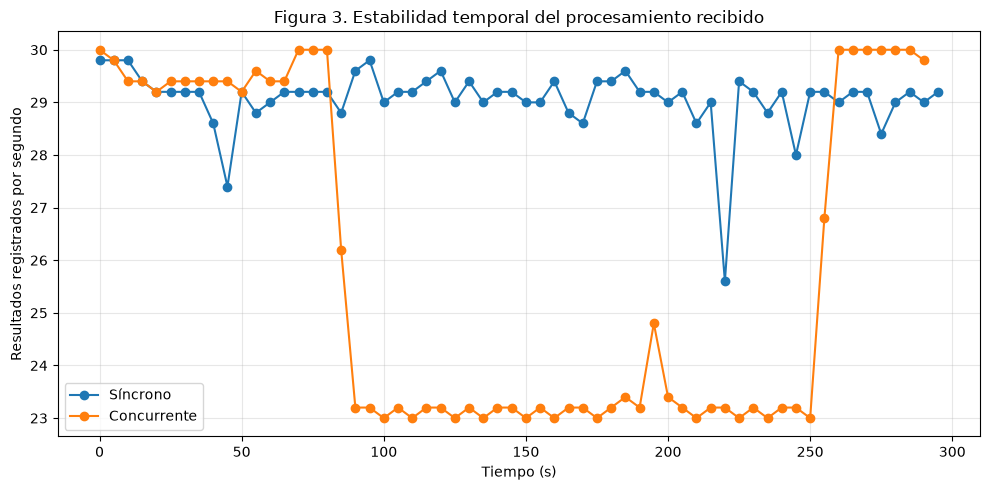

In [38]:
plt.figure(figsize=(10, 5))

plt.plot(fps_sync["time"], fps_sync["fps"], marker="o", label="Síncrono")
plt.plot(fps_async["time"], fps_async["fps"], marker="o", label="Concurrente")

plt.title("Figura 3. Estabilidad temporal del procesamiento recibido")

plt.xlabel("Tiempo (s)")
plt.ylabel("Resultados registrados por segundo")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La arquitectura síncrona mantuvo un rendimiento cercano a 29 FPS durante los cinco minutos de evaluación, con fluctuaciones puntuales y recuperaciones rápidas. En contraste, la arquitectura concurrente presentó tres fases diferenciadas: un rendimiento inicial cercano a 30 FPS, una reducción sostenida hasta aproximadamente 23 FPS entre los segundos 85 y 255, y una recuperación posterior

Este comportamiento evidencia una mayor variabilidad temporal del pipeline concurrente, mientras que el síncrono mantuvo una tasa de resultados más constante

### Variabilidad del rendimiento

In [39]:
stability_comparison = pd.DataFrame({
    "Arquitectura": ["Síncrono", "Concurrente"],
    "FPS promedio": [fps_sync["fps"].mean(), fps_async["fps"].mean()],
    "Desviación estándar": [fps_sync["fps"].std(), fps_async["fps"].std()],
    "FPS mínimo": [fps_sync["fps"].min(), fps_async["fps"].min()]
})

display(stability_comparison.round(2))

,Arquitectura,FPS promedio,Desviación estándar,FPS mínimo
0,Síncrono,29.07,0.60,25.6
1,Concurrente,25.94,3.19,23.0


### Identificación de cuellos de botella

In [40]:
stage_comparison = pd.DataFrame({
    "Etapa": [
        "Captura",
        "Preprocesamiento",
        "Inferencia",
        "Preparación visual"
    ],
    "Síncrono (ms)": [
        df_sync["capture_ms"].mean(),
        df_sync["preprocess_ms"].mean(),
        df_sync["inference_ms"].mean(),
        df_sync["render_ms"].mean()
    ],
    "Concurrente (ms)": [
        df_async["capture_ms"].mean(),
        df_async["preprocess_ms"].mean(),
        df_async["inference_ms"].mean(),
        df_async["render_ms"].mean()
    ]
})

display(stage_comparison.round(2))

,Etapa,Síncrono (ms),Concurrente (ms)
0,Captura,13.89,38.43
1,Preprocesamiento,0.20,0.17
2,Inferencia,19.85,19.74
3,Preparación visual,0.32,0.33


In [41]:
inference_comparison = pd.DataFrame({
    "Arquitectura": ["Síncrono", "Concurrente"],
    "Inferencia media (ms)": [
        df_sync["inference_ms"].mean(),
        df_async["inference_ms"].mean()
    ],
    "Inferencia P95 (ms)": [
        df_sync["inference_ms"].quantile(0.95),
        df_async["inference_ms"].quantile(0.95)
    ]
})

display(inference_comparison.round(2))

,Arquitectura,Inferencia media (ms),Inferencia P95 (ms)
0,Síncrono,19.85,21.83
1,Concurrente,19.74,22.77


### Consumo de CPU y memoria

In [42]:
resource_comparison = pd.DataFrame({
    "Arquitectura": ["Síncrono", "Concurrente"],
    "CPU promedio (%)": [
        summary_sync["cpu_mean_percent"],
        summary_async["cpu_mean_percent"]
    ],
    "Memoria máxima (MB)": [
        summary_sync["memory_peak_mb"],
        summary_async["memory_peak_mb"]
    ]
})

display(resource_comparison.round(2))

,Arquitectura,CPU promedio (%),Memoria máxima (MB)
0,Síncrono,66.80,501.05
1,Concurrente,59.18,524.81


## Calidad de las detecciones y correspondencia temporal

In [ ]:
validation_results = []

for name, df in [("Síncrono", df_sync), ("Concurrente", df_async)]:
    validation_results.append({
        "Arquitectura": name,
        "IDs únicos": df["frame_id"].is_unique,
        "IDs ordenados": (df["frame_id"].is_monotonic_increasing),
        "Tiempo ordenado": (df["timestamp"].is_monotonic_increasing),
        "Latencias válidas": ((df["latency_ms"] >= 0).all())
    })

validation_df = pd.DataFrame(validation_results)
display(validation_df)

,Arquitectura,IDs únicos,IDs ordenados,Tiempo ordenado,Latencias válidas
0,Síncrono,True,True,True,True
1,Concurrente,True,True,True,True


### Calidad operativa de la detección

In [44]:
detection_comparison = pd.DataFrame({
    "Arquitectura": ["Síncrono", "Concurrente"],
    "Resultados registrados": [
        len(df_sync),
        len(df_async)
    ],
    "Con manos detectadas (%)": [
        ((df_sync["hands_detected"] > 0).mean() * 100),
        ((df_async["hands_detected"] > 0).mean() * 100)
    ],
    "Manos promedio": [
        df_sync["hands_detected"].mean(),
        df_async["hands_detected"].mean()
    ]
})

display(detection_comparison.round(2))

,Arquitectura,Resultados registrados,Con manos detectadas (%),Manos promedio
0,Síncrono,8721,99.15,1.80
1,Concurrente,7803,100.00,1.83


### Guardar resultados

In [45]:
comparison.to_csv(RESULTS_DIR / "comparison.csv",index=False)
stage_comparison.to_csv(RESULTS_DIR / "stage_comparison.csv", index=False)
stability_comparison.to_csv(RESULTS_DIR / "stability_comparison.csv", index=False)

print("Resultados guardados en:", RESULTS_DIR)

Resultados guardados en: results
